In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(r'C:\Users\Acer\OneDrive\Desktop\Student-Performance-Prediction\dataset\StudentsPerformance.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1000, 8)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [6]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [7]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Duplicate Records: 0


In [8]:
# Remove duplicate records
df.drop_duplicates(inplace=True)

# Check missing values
df.isnull().sum()

print("Data cleaning completed!")

Data cleaning completed!


In [9]:
print("Dataset Shape After Cleaning:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape After Cleaning: (1000, 8)

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


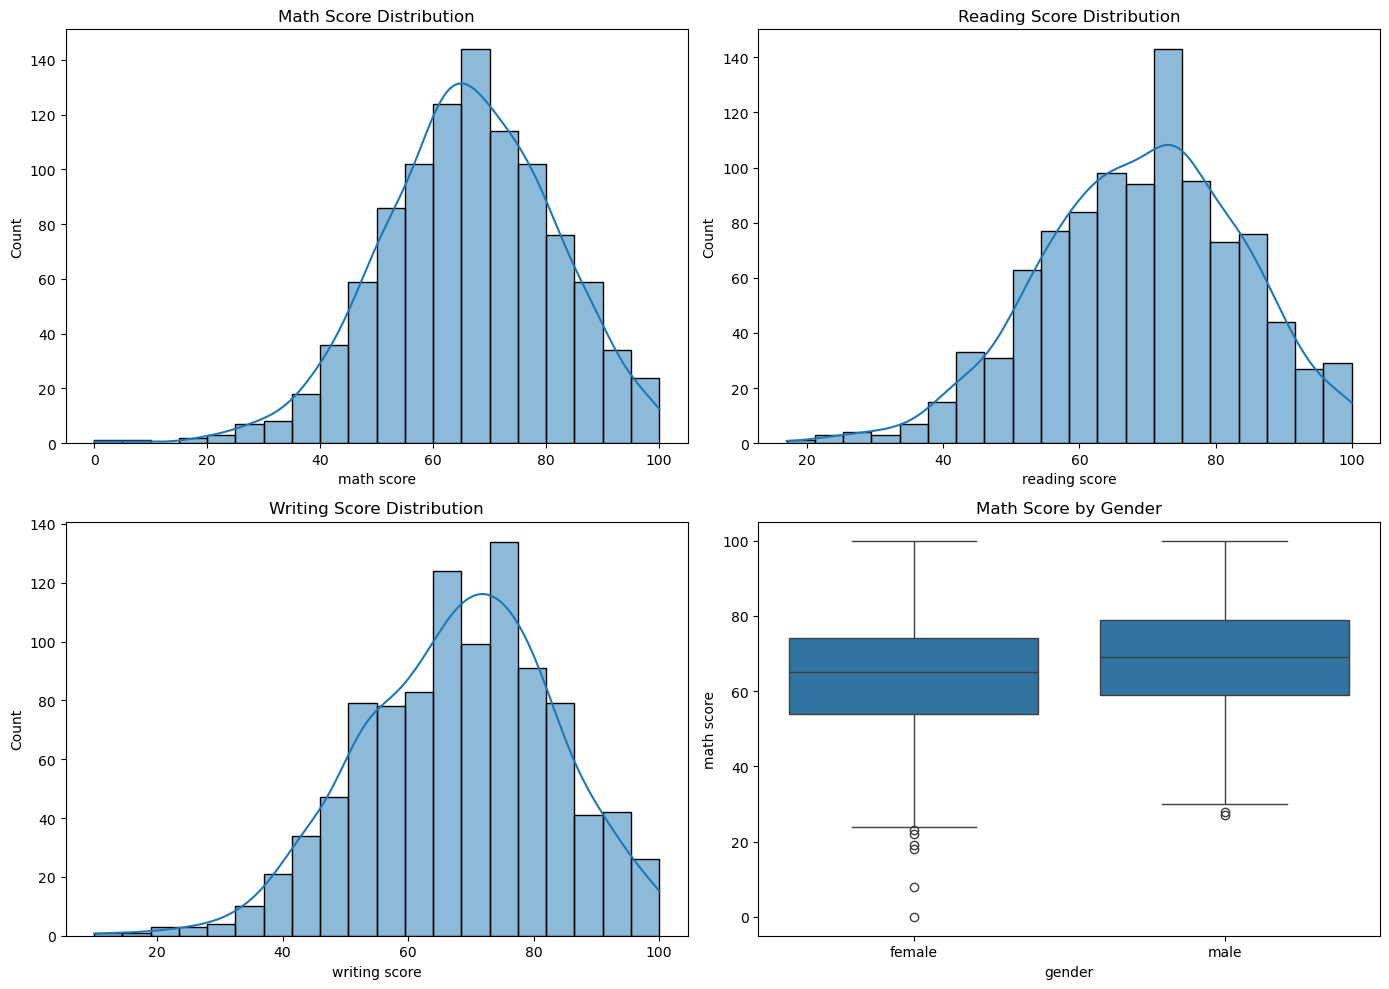

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Math Score Distribution
sns.histplot(df['math score'], bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Math Score Distribution')

# Reading Score Distribution
sns.histplot(df['reading score'], bins=20, kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Reading Score Distribution')

# Writing Score Distribution
sns.histplot(df['writing score'], bins=20, kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Writing Score Distribution')

# Math Score by Gender
sns.boxplot(data=df, x='gender', y='math score', ax=axes[1, 1])
axes[1, 1].set_title('Math Score by Gender')

plt.tight_layout()
plt.show()

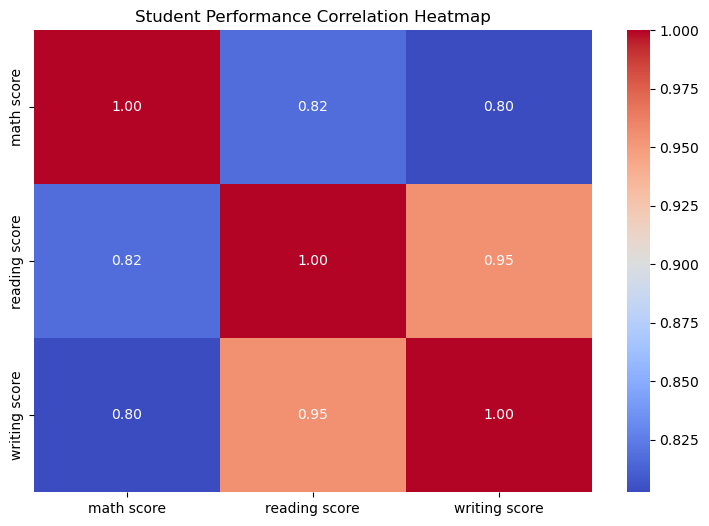

In [11]:
plt.figure(figsize=(9, 6))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Student Performance Correlation Heatmap')
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Create a copy of the dataset
data = df.copy()

# Encode categorical columns
categorical_columns = [
    'gender',
    'race/ethnicity',
    'parental level of education',
    'lunch',
    'test preparation course'
]

for col in categorical_columns:
    data[col] = LabelEncoder().fit_transform(data[col])

# Separate features and target
X = data.drop('math score', axis=1)
y = data['math score']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data preparation completed!")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Data preparation completed!
Training records: 800
Testing records: 200


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predictions
lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Evaluation
print("LINEAR REGRESSION")
print("MAE:", round(mean_absolute_error(y_test, lr_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, lr_pred)), 2))
print("R2 Score:", round(r2_score(y_test, lr_pred), 3))

print("\nRANDOM FOREST")
print("MAE:", round(mean_absolute_error(y_test, rf_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_pred)), 2))
print("R2 Score:", round(r2_score(y_test, rf_pred), 3))

LINEAR REGRESSION
MAE: 4.13
RMSE: 5.32
R2 Score: 0.884

RANDOM FOREST
MAE: 4.7
RMSE: 6.07
R2 Score: 0.849


In [15]:
import joblib
import os

model_path = r'C:\Users\Acer\OneDrive\Desktop\Student-Performance-Prediction\models'

os.makedirs(model_path, exist_ok=True)

joblib.dump(rf_model, os.path.join(model_path, 'student_performance_model.pkl'))

print("Model saved successfully!")

Model saved successfully!
